# Gravidade de acidentes nas rodovias federais — Equipe 9

Este notebook é a análise de Data Science do projeto.
O código de limpeza fica em `src/`. A app em Streamlit usa o mesmo código.

**Roteiro do Checkpoint 1**

1. Entendimento do negócio e dos dados (CRISP-DM)
2. Preparação dos dados (Data Wrangling)
3. Regressão linear múltipla *(próxima etapa)*
4. Clustering K-Means *(próxima etapa)*

## 1. Entendimento do negócio

**Problema.** As rodovias federais têm cerca de 70 mil acidentes por ano. Cerca de 7% desses acidentes têm pelo menos uma morte.

**Pergunta central.** O que faz um acidente numa rodovia federal ser fatal?

**Hipótese de intervenção.** A duplicação de trechos de pista simples reduz a chance de um acidente ser fatal.

**Decisão que o projeto apoia.** Se a hipótese for verdadeira, o projeto indica os trechos onde a duplicação tem o maior ganho.

**Critério de sucesso.** O modelo identifica os acidentes fatais com recall e precisão melhores que um modelo de base.
A acurácia não serve como critério: um modelo que sempre diz "não fatal" acerta cerca de 93% dos casos.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from carregar import carregar
from colunas import ADMINISTRATIVAS, ALVO, VAZAMENTO
from limpeza import (
    LIMITES_BRASIL,
    VARIANTES_CAUSA,
    agrupar_categorias,
    marcar_faltantes,
    padronizar_textos,
    remover_coordenadas_invalidas,
    remover_duplicatas,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

ANOS = range(2017, 2026)

## 2. Entendimento dos dados

**Fonte.** [Dados abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf), agrupados por ocorrência. Cada linha é um acidente.

**Período.** De 2017 a 2025. O arquivo de 2026 fica fora, porque o ano ainda não terminou.

**Leitura.** A função `carregar()` faz cinco operações em cada arquivo:

1. Lê o CSV (`latin1`, separador `;`).
2. Confere se as colunas obrigatórias existem.
3. Remove as colunas administrativas (`id`, `regional`, `delegacia`, `uop`).
4. Converte a vírgula decimal de `latitude`, `longitude` e `km` e converte as datas.
5. Remove as linhas sem classificação (10 linhas de 2017 a 2025) e cria o alvo `fatal`.

O campo `tracado_via` pode ter mais de um valor separado por `;`, por exemplo `"Reta;Declive"`.
O CSV coloca esses valores entre aspas, então a leitura não divide o campo. Todas as linhas têm 30 campos.

In [2]:
partes = []

for ano in ANOS:
    partes.append(carregar(f"../data/raw/datatran{ano}.csv"))

df_bruto = pd.concat(partes, ignore_index=True)
df_bruto["ano"] = df_bruto["data_inversa"].dt.year

print(f"Acidentes carregados: {len(df_bruto):,}".replace(",", "."))

Acidentes carregados: 632.703


### 2.1 Inspeção da estrutura

In [3]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 632703 entries, 0 to 632702
Data columns (total 28 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   data_inversa            632703 non-null  datetime64[us]
 1   dia_semana              632703 non-null  str           
 2   horario                 632703 non-null  str           
 3   uf                      632703 non-null  str           
 4   br                      632703 non-null  Int64         
 5   km                      632703 non-null  float64       
 6   municipio               632703 non-null  str           
 7   causa_acidente          632703 non-null  str           
 8   tipo_acidente           632663 non-null  str           
 9   classificacao_acidente  632703 non-null  str           
 10  fase_dia                632703 non-null  str           
 11  sentido_via             632703 non-null  str           
 12  condicao_metereologica  632703 non-null  

As colunas de vítimas (`mortos`, `feridos`, `ilesos` e outras) ficam como texto. O modelo não usa essas colunas,
porque elas descrevem o resultado do acidente (vazamento do alvo):

In [4]:
print("Vazamento:", ", ".join(VAZAMENTO))
print("Administrativas (já removidas):", ", ".join(ADMINISTRATIVAS))

Vazamento: classificacao_acidente, mortos, feridos_leves, feridos_graves, feridos, ilesos, ignorados
Administrativas (já removidas): id, regional, delegacia, uop


In [5]:
df_bruto[["km", "pessoas", "veiculos", "latitude", "longitude"]].describe().round(2)

,km,pessoas,veiculos,latitude,longitude
count,632703.00,632703.0,632703.0,6.327030e+05,6.327030e+05
mean,260.30,2.53,1.96,-1.720370e+03,-6.545700e+03
std,227.49,2.05,1.09,1.299726e+06,5.050540e+06
min,0.00,1.0,1.0,-1.033383e+09,-4.016764e+09
25%,76.90,2.0,1.0,-2.525000e+01,-5.025000e+01
50%,194.40,2.0,2.0,-2.041000e+01,-4.767000e+01
75%,409.00,3.0,2.0,-1.275000e+01,-4.252000e+01
max,1470.00,95.0,131.0,1.630000e+02,7.170000e+02


O `describe()` mostra dois problemas:

- `latitude` e `longitude` têm valores impossíveis (por exemplo, uma longitude de −4 bilhões).
- `pessoas` e `veiculos` têm valores extremos (até 95 pessoas e 131 veículos).

A seção 3.5 trata os dois problemas.

In [6]:
df_bruto.select_dtypes(include="str").describe().T

,count,unique,top,freq
dia_semana,632703,7,sábado,104336
horario,632703,1440,19:00:00,9190
uf,632703,27,MG,83427
municipio,632703,2156,BRASILIA,9039
causa_acidente,632703,91,Falta de Atenção à Condução,107786
tipo_acidente,632663,21,Colisão traseira,119331
classificacao_acidente,632703,3,Com Vítimas Feridas,462965
fase_dia,632703,4,Pleno dia,347240
sentido_via,632703,3,Crescente,337627
condicao_metereologica,632703,10,Céu Claro,377737


### 2.2 O alvo: acidentes fatais por ano

In [7]:
por_ano = df_bruto.groupby("ano").agg(acidentes=(ALVO, "size"), fatais=(ALVO, "sum"))
por_ano["% fatais"] = (por_ano["fatais"] / por_ano["acidentes"] * 100).round(2)
por_ano

,acidentes,fatais,% fatais
ano,,,
2017,89566,5184,5.79
2018,69332,4508,6.50
2019,67557,4599,6.81
2020,63583,4525,7.12
2021,64566,4665,7.23
2022,64605,4664,7.22
2023,67765,4858,7.17
2024,73201,5225,7.14
2025,72528,5209,7.18


A classe fatal é a minoria (cerca de 7%). Os modelos precisam de pesos de classe ou de um limiar de decisão ajustado.

Em 2017, a taxa de fatais é mais baixa (5,8%) que nos outros anos. Os dados não mostram a causa dessa diferença.

### 2.3 Evidência inicial da hipótese

In [8]:
frontal = df_bruto[df_bruto["tipo_acidente"] == "Colisão frontal"]

evidencia = pd.DataFrame({
    "acidentes": df_bruto.groupby("tipo_pista").size(),
    "% fatais": df_bruto.groupby("tipo_pista")[ALVO].mean() * 100,
    "% fatais em colisão frontal": frontal.groupby("tipo_pista")[ALVO].mean() * 100,
}).round(1)

evidencia.loc[["Simples", "Dupla", "Múltipla"]]

,acidentes,% fatais,% fatais em colisão frontal
tipo_pista,,,
Simples,315718,9.3,30.0
Dupla,263068,4.6,16.6
Múltipla,53917,3.9,11.3


Na pista simples, a taxa de fatais é cerca de duas vezes a taxa da pista dupla.
Esta comparação não controla outros fatores (clima, causa, traçado). As próximas etapas fazem esse controle.

## 3. Preparação dos dados (Data Wrangling)

Cada passo tem três partes: o problema, a evidência nos dados e a ação.
As funções ficam em `src/limpeza.py`, e os testes ficam em `tests/test_limpeza.py`.

### 3.1 Duplicatas

**Problema.** Alguns acidentes estão registrados duas vezes, com `id` diferente e todas as outras colunas iguais.

**Ação.** Remova as linhas repetidas. O `carregar()` já removeu o `id`, então duas linhas iguais são o mesmo acidente.

In [9]:
duplicadas = df_bruto[df_bruto.duplicated(keep=False)]
print(f"Linhas repetidas: {df_bruto.duplicated().sum()}")

duplicadas[["data_inversa", "horario", "uf", "br", "km", "tipo_acidente", "classificacao_acidente"]].sort_values(["data_inversa", "horario"]).head(6)

Linhas repetidas: 10


,data_inversa,horario,uf,br,km,tipo_acidente,classificacao_acidente
19235,2017-10-20,14:25:00,SC,282,483.9,Colisão traseira,Sem Vítimas
75524,2017-10-20,14:25:00,SC,282,483.9,Colisão traseira,Sem Vítimas
79146,2017-11-11,17:00:00,GO,60,201.8,Colisão com objeto estático,Sem Vítimas
79147,2017-11-11,17:00:00,GO,60,201.8,Colisão com objeto estático,Sem Vítimas
80532,2017-11-19,15:40:00,RJ,40,113.0,Colisão traseira,Com Vítimas Feridas
80533,2017-11-19,15:40:00,RJ,40,113.0,Colisão traseira,Com Vítimas Feridas


In [10]:
df = remover_duplicatas(df_bruto)
print(f"Antes: {len(df_bruto)} linhas. Depois: {len(df)} linhas.")

Antes: 632703 linhas. Depois: 632693 linhas.


### 3.2 Valores faltantes escritos como texto

**Problema.** A PRF escreve alguns valores faltantes como texto. Para o pandas, esses textos são categorias válidas.

| Coluna | Texto | Significado |
|---|---|---|
| `condicao_metereologica` | `"Ignorado"` | O clima não foi registrado |
| `sentido_via` | `"Não Informado"` | O sentido não foi registrado |
| `br` | `0` | A rodovia não foi registrada |

Quando `br` é 0, `km` também é 0 e `sentido_via` é `"Não Informado"`. A PRF não registrou o ponto do acidente na rodovia.

**Ação.** Mude esses valores para `NaN`. Mude também o `km` das linhas com `br` = 0.

In [11]:
sem_rodovia = df["br"] == 0

print("Clima 'Ignorado':", (df["condicao_metereologica"] == "Ignorado").sum())
print("Sentido 'Não Informado':", (df["sentido_via"] == "Não Informado").sum())
print("br = 0:", sem_rodovia.sum())
print("br = 0 com km = 0 e sentido 'Não Informado':", (sem_rodovia & (df["km"] == 0) & (df["sentido_via"] == "Não Informado")).sum())

Clima 'Ignorado': 8947
Sentido 'Não Informado': 1407
br = 0: 1407
br = 0 com km = 0 e sentido 'Não Informado': 1407


In [12]:
df = marcar_faltantes(df)

faltantes = df.isna().sum()
faltantes[faltantes > 0].to_frame("NaN")

,NaN
br,1407
km,1407
tipo_acidente,40
sentido_via,1407
condicao_metereologica,8947


### 3.3 Padronização de textos

**Problema 1.** Algumas causas mudaram de grafia entre os anos, mas o conceito não mudou.

In [13]:
variantes = df[df["causa_acidente"].isin(set(VARIANTES_CAUSA) | set(VARIANTES_CAUSA.values()))]
pd.crosstab(variantes["causa_acidente"], variantes["ano"])

ano,2018,2019,2020,2021,2022,2023,2024,2025
causa_acidente,,,,,,,,
Ingestão de álcool e/ou substâncias psicoativas pelo pedestre,247,334,305,297,264,217,0,0
Ingestão de álcool ou de substâncias psicoativas pelo pedestre,0,1,1,114,72,94,0,0
Pedestre - Ingestão de álcool/ substâncias psicoativas,0,0,0,0,0,4,169,150
Transitar no Acostamento,0,0,0,0,0,271,488,498
Transitar no acostamento,0,0,4,446,377,0,0,0


**Problema 2.** O campo `tracado_via` junta vários valores com `;`, em qualquer ordem. Por exemplo, `"Reta;Declive"` e `"Declive;Reta"` são o mesmo traçado.

**Ação.** Substitua cada variante pelo texto mais recente. Coloque as partes do traçado em ordem alfabética.

In [14]:
antes = df["tracado_via"].nunique()

df = padronizar_textos(df)

print(f"Textos diferentes em tracado_via: {antes} antes, {df['tracado_via'].nunique()} depois.")
print(f"Valores básicos do traçado: {df['tracado_via'].str.split(';').explode().nunique()}")

Textos diferentes em tracado_via: 1328 antes, 384 depois.
Valores básicos do traçado: 12


### 3.4 Mudança das categorias em 2021

**Problema.** Em 2021, a PRF trocou a lista de causas e de tipos de acidente. O dicionário de dados não documenta essa mudança.

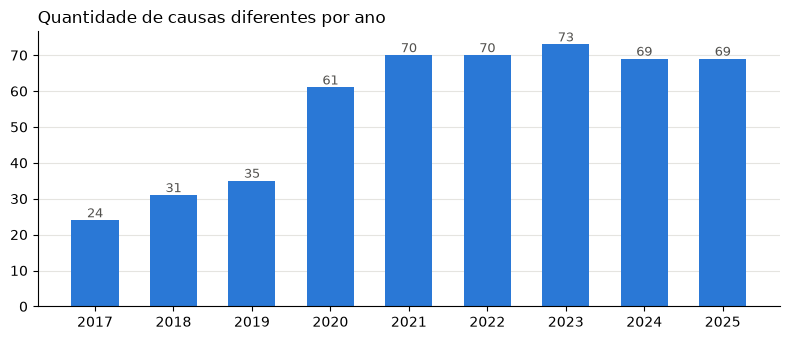

In [15]:
causas_por_ano = df.groupby("ano")["causa_acidente"].nunique()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(causas_por_ano.index, causas_por_ano.values, color="#2a78d6", width=0.6)
ax.set_title("Quantidade de causas diferentes por ano", loc="left")
ax.set_xticks(causas_por_ano.index)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0")
ax.set_axisbelow(True)

for ano, total in causas_por_ano.items():
    ax.annotate(str(total), (ano, total), ha="center", va="bottom", fontsize=9, color="#52514e")

plt.tight_layout()
plt.show()

In [16]:
contagem = pd.crosstab(df["causa_acidente"], df["ano"])
antigas = contagem.loc[:, :2019].sum(axis=1) > 0
novas = contagem.loc[:, 2021:].sum(axis=1) > 0

print(f"Causas que desaparecem depois de 2020: {(antigas & ~novas).sum()}")
print(f"Causas que existem nos dois períodos: {(antigas & novas).sum()}")
print(f"Causas que começam em 2020 ou 2021: {(~antigas & novas).sum()}")

contagem[antigas & ~novas].sort_values(2017, ascending=False).head(8)

Causas que desaparecem depois de 2020: 15
Causas que existem nos dois períodos: 23
Causas que começam em 2020 ou 2021: 50


ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
causa_acidente,,,,,,,,,
Falta de Atenção à Condução,34510,25840,25030,22406,0,0,0,0,0
Ingestão de Álcool,6448,5203,5420,5070,0,0,0,0,0
Não guardar distância de segurança,5836,4266,4222,3606,0,0,0,0,0
Desobediência às normas de trânsito pelo condutor,5219,7194,8106,8800,0,0,0,0,0
Defeito Mecânico no Veículo,4649,3717,3742,3742,0,0,0,0,0
Falta de Atenção do Pedestre,2390,2074,1971,1641,0,0,0,0,0
Defeito na Via,1420,1128,978,960,0,0,0,0,0
Mal Súbito,972,677,718,584,0,0,0,0,0


Em 2020, as causas novas já aparecem, mas cada uma tem menos de 40 registros. A troca completa acontece em 2021.

A maior causa de 2017 ("Falta de Atenção à Condução", 38% dos acidentes) não existe depois de 2020.
No lugar dela aparecem causas mais detalhadas, por exemplo "Reação tardia ou ineficiente do condutor".

A coluna `tipo_acidente` também muda:

In [17]:
tipos_alterados = ["Colisão com objeto estático", "Colisão com objeto em movimento", "Colisão com objeto",
                   "Colisão lateral", "Colisão lateral mesmo sentido", "Colisão lateral sentido oposto"]

pd.crosstab(df["tipo_acidente"], df["ano"]).loc[tipos_alterados]

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
tipo_acidente,,,,,,,,,
Colisão com objeto estático,7327,5061,4464,4889,0,0,0,0,0
Colisão com objeto em movimento,627,399,313,255,0,0,0,0,0
Colisão com objeto,1,0,0,27,4910,4764,4859,5121,5109
Colisão lateral,10599,8347,8347,7439,676,0,0,0,0
Colisão lateral mesmo sentido,0,1,0,12,5572,6239,7004,7906,7885
Colisão lateral sentido oposto,0,0,1,9,1609,1774,2018,2029,2152


**Ação.** O notebook mantém duas colunas para cada campo:

| Coluna | Conteúdo | Uso |
|---|---|---|
| `causa_acidente` | Texto original, com a grafia padronizada (73 causas de 2021 a 2025) | Modelos com detalhe (por exemplo, embeddings) |
| `grupo_causa` | 10 grupos que juntam as causas antigas e as novas | Comparações entre todos os anos |
| `tipo_acidente` | Texto original | Modelos com detalhe |
| `grupo_tipo` | Tipos com nomes iguais nos dois períodos | Comparações entre todos os anos |

Os grupos de causa estão em `GRUPOS_CAUSA` (`src/limpeza.py`). "Desatenção" e "infração" ficam no mesmo grupo ("Falha do condutor"),
porque, em 2021, registros passaram de uma categoria para a outra.

In [18]:
df = agrupar_categorias(df)

print(f"Causas sem grupo: {df['grupo_causa'].isna().sum()}")
print(f"Grupos de causa: {df['grupo_causa'].nunique()}")
print(f"Grupos de tipo: {df['grupo_tipo'].nunique()}")

Causas sem grupo: 0
Grupos de causa: 10
Grupos de tipo: 15


**Teste do mapeamento.** Se os grupos estão corretos, a proporção de cada grupo não muda muito de 2020 para 2021.

In [19]:
proporcao = (pd.crosstab(df["grupo_causa"], df["ano"], normalize="columns") * 100).round(1)
proporcao["variação 2020→2021"] = (proporcao[2021] - proporcao[2020]).round(1)
proporcao.sort_values(2021, ascending=False)

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025,variação 2020→2021
grupo_causa,,,,,,,,,,
Falha do condutor,53.2,55.7,57.0,56.7,55.4,59.6,63.8,65.2,66.5,-1.3
Velocidade,11.6,9.9,8.9,9.3,10.5,7.8,6.3,6.0,5.7,1.2
Veículo,7.8,7.6,7.4,8.2,7.6,7.3,7.4,7.4,7.3,-0.6
Álcool e drogas (condutor),7.3,7.7,8.2,8.2,7.3,6.9,5.4,5.4,5.2,-0.9
Via,2.9,2.8,2.5,2.6,5.1,4.8,4.4,3.7,3.8,2.5
Estado físico (condutor),5.3,4.8,4.7,4.2,4.6,4.2,4.0,4.0,4.0,0.4
Clima e natureza,6.2,4.9,4.3,4.3,4.2,3.9,3.4,3.5,3.0,-0.1
Pedestre,2.7,3.7,4.0,3.7,3.5,3.6,3.3,2.8,2.7,-0.2
Animais,2.9,2.3,2.3,2.2,1.9,2.0,2.0,2.0,1.8,-0.3


In [20]:
taxa_fatal = (df.pivot_table(index="grupo_causa", columns="ano", values=ALVO, aggfunc="mean") * 100).round(1)
taxa_fatal.sort_values(2021, ascending=False)

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
grupo_causa,,,,,,,,,
Pedestre,29.3,27.1,27.4,29.2,30.9,28.8,28.2,32.1,31.3
Velocidade,7.2,8.7,9.6,9.8,8.5,8.2,9.1,8.4,9.5
Estado físico (condutor),9.4,10.3,10.3,9.5,8.5,8.2,9.7,10.9,11.1
Falha do condutor,4.8,5.3,5.6,6.1,6.8,6.9,6.7,6.7,6.7
Via,4.4,5.4,4.4,5.4,5.7,6.4,5.9,6.3,5.8
Animais,3.6,5.7,5.4,4.9,4.7,6.1,6.8,5.5,5.5
Clima e natureza,4.1,5.1,5.5,4.7,4.7,4.2,3.8,4.5,3.6
Álcool e drogas (condutor),6.4,5.1,5.5,5.8,4.2,4.1,4.4,4.6,4.9
Veículo,2.3,3.0,3.3,3.9,2.7,3.0,2.9,2.5,2.5


**Resultado do teste.**

- Oito grupos têm uma variação de até 1,3 ponto percentual de 2020 para 2021. A taxa de fatais de cada grupo também fica estável.
- O grupo "Via" dobra (2,6% → 5,1%). A lista nova tem 26 causas de via, e a lista antiga tinha 3. Esta quebra é real e o mapeamento não corrige.
- O grupo "Agressão externa" desaparece depois de 2020.
- Em 2017, a taxa de fatais é mais baixa em quase todos os grupos.

Conclusão: `grupo_causa` permite comparar todos os anos, com as limitações acima.

### 3.5 Outliers

**Problema 1: coordenadas fora do Brasil.** Alguns registros têm latitude ou longitude fora do território brasileiro.
Muitos parecem ter um erro de digitação na vírgula decimal (por exemplo, longitude −405,9 no lugar de −40,59).

**Ação.** Mude a latitude e a longitude desses registros para `NaN`. Não tente corrigir o valor, porque a posição correta da vírgula é uma suposição.

In [21]:
fora = pd.Series(False, index=df.index)
for coluna, (minimo, maximo) in LIMITES_BRASIL.items():
    fora |= (df[coluna] < minimo) | (df[coluna] > maximo)

print(f"Registros fora do Brasil: {fora.sum()}")
print(df.loc[fora, "ano"].value_counts().to_dict())

df.loc[fora, ["ano", "uf", "municipio", "latitude", "longitude"]].head(6)

Registros fora do Brasil: 54
{2017: 53, 2024: 1}


,ano,uf,municipio,latitude,longitude
9,2017,BA,RIO REAL,-50.199409,-94.499996
69,2017,MG,GRAO MOGOL,0.000000,0.000000
113,2017,MG,ESTIVA,-22.418505,-405.964614
116,2017,RJ,PETROPOLIS,-22.423555,-763.156813
134,2017,BA,JAGUAQUARA,13.000000,40.000000
165,2017,BA,PRESIDENTE TANCREDO NEVES,12.554564,-411.328125


In [22]:
df = remover_coordenadas_invalidas(df)
df[["latitude", "longitude"]].describe().round(2)

,latitude,longitude
count,632639.00,632639.00
mean,-18.86,-46.58
std,7.75,6.18
min,-33.71,-72.67
25%,-25.25,-50.25
50%,-20.41,-47.67
75%,-12.75,-42.52
max,4.48,-34.00


**Problema 2: acidentes com muitas pessoas ou muitos veículos.** A regra do intervalo interquartil (IQR) marca como outlier
um valor acima de Q3 + 1,5 × IQR.

In [23]:
linhas = {}

for coluna in ["pessoas", "veiculos"]:
    valores = df[coluna].astype(float)
    q1, q3 = valores.quantile([0.25, 0.75])
    limite = q3 + 1.5 * (q3 - q1)
    acima = valores > limite

    linhas[coluna] = {
        "limite IQR": limite,
        "acidentes acima": int(acima.sum()),
        "% dos acidentes": round(acima.mean() * 100, 1),
        "% fatais acima": round(df.loc[acima, ALVO].mean() * 100, 1),
        "% fatais abaixo": round(df.loc[~acima, ALVO].mean() * 100, 1),
        "máximo": int(valores.max()),
    }

pd.DataFrame(linhas).T

,limite IQR,acidentes acima,% dos acidentes,% fatais acima,% fatais abaixo,máximo
pessoas,4.5,52703.0,8.3,15.0,6.1,95.0
veiculos,3.5,43796.0,6.9,14.0,6.3,131.0


In [24]:
df.nlargest(3, "veiculos")[["data_inversa", "uf", "br", "tipo_acidente", "pessoas", "veiculos", "classificacao_acidente"]]

,data_inversa,uf,br,tipo_acidente,pessoas,veiculos,classificacao_acidente
436758,2023-09-02,PR,277,Colisão traseira,95,131,Com Vítimas Fatais
570424,2025-07-07,GO,80,Incêndio,2,82,Sem Vítimas
171918,2019-10-15,MG,40,Saída de leito carroçável,3,38,Com Vítimas Fatais


**Decisão: os acidentes com muitas pessoas ou veículos ficam na base.**

- A regra IQR marca cerca de 8% dos acidentes. Esses acidentes têm uma taxa de fatais de 15%, contra 6% nos outros.
  Se removermos esses acidentes, removemos uma parte importante do sinal que o modelo precisa aprender.
- O maior valor é uma colisão traseira com 131 veículos e 95 pessoas, com vítimas fatais (BR-277, PR, 2023). Os dados não mostram erro nesse registro.
- Nas etapas que usam distância ou escala (K-Means, regressão), a etapa de modelagem trata esses valores.

### 3.6 Tratamento de `NaN`

Depois da limpeza, estas colunas ainda têm `NaN`:

In [25]:
faltantes = df.isna().sum()
pd.DataFrame({"NaN": faltantes, "%": (faltantes / len(df) * 100).round(2)})[faltantes > 0]

,NaN,%
br,1407,0.22
km,1407,0.22
tipo_acidente,40,0.01
sentido_via,1407,0.22
condicao_metereologica,8947,1.41
latitude,54,0.01
longitude,54,0.01
grupo_tipo,40,0.01


**Decisão: o preenchimento dos `NaN` acontece depois da divisão treino/teste.**

- Se o preenchimento usar a base inteira (por exemplo, a mediana), o treino recebe informação do teste (*data leakage*).
- O pipeline (`src/features/encoding.py`) calcula a mediana das colunas numéricas só no treino.
- Nas colunas categóricas, o `NaN` vira uma categoria própria. A falta de registro também pode ser informação.
- As colunas de vítimas têm `NaN`, mas não entram no modelo (vazamento).

### 3.7 Resumo da limpeza

In [26]:
resumo = pd.DataFrame({
    "antes": [
        len(df_bruto),
        df_bruto.duplicated().sum(),
        (df_bruto["condicao_metereologica"] == "Ignorado").sum(),
        (df_bruto["sentido_via"] == "Não Informado").sum(),
        (df_bruto["br"] == 0).sum(),
        df_bruto["tracado_via"].nunique(),
        df_bruto["causa_acidente"].nunique(),
        df_bruto["tipo_acidente"].nunique(),
        ((df_bruto["latitude"] < -34) | (df_bruto["latitude"] > 5.5) | (df_bruto["longitude"] < -74) | (df_bruto["longitude"] > -34)).sum(),
    ],
    "depois": [
        len(df),
        df.duplicated().sum(),
        (df["condicao_metereologica"] == "Ignorado").sum(),
        (df["sentido_via"] == "Não Informado").sum(),
        (df["br"] == 0).sum(),
        df["tracado_via"].nunique(),
        df["causa_acidente"].nunique(),
        df["grupo_tipo"].nunique(),
        ((df["latitude"] < -34) | (df["latitude"] > 5.5) | (df["longitude"] < -74) | (df["longitude"] > -34)).sum(),
    ],
}, index=[
    "linhas",
    "linhas repetidas",
    "clima 'Ignorado'",
    "sentido 'Não Informado'",
    "br = 0",
    "textos diferentes em tracado_via",
    "causas diferentes",
    "tipos de acidente (depois: grupo_tipo)",
    "coordenadas fora do Brasil",
])

resumo

,antes,depois
linhas,632703,632693
linhas repetidas,10,0
clima 'Ignorado',8947,0
sentido 'Não Informado',1407,0
br = 0,1407,0
textos diferentes em tracado_via,1328,384
causas diferentes,91,88
tipos de acidente (depois: grupo_tipo),21,15
coordenadas fora do Brasil,54,0


### 3.8 Limitações dos dados

- A PRF registra os acidentes, mas não registra o fluxo de veículos. Sem o fluxo, não é possível calcular o risco por veículo.
- O agente da PRF anota a causa no local do acidente. A causa é uma opinião, não uma medição.
- A lista de causas mudou em 2021. O `grupo_causa` reduz o problema, mas o grupo "Via" ainda tem uma quebra.
- Os dados cobrem só as rodovias federais.